## Table of Contents
1. [Overview](#1-overview)
2. [Load Processed Data](#2-load-processed-data)
3. [Train / Validation Split](#3-train--validation-split)
4. [Baseline XGBoost Model (All 34 Features)](#4-baseline-xgboost-model-all-34-features)
5. [Feature Ablation Study (Leave-One-Out)](#5-feature-ablation-study-leave-one-out)
6. [Multi-Season Cross-Validation](#6-multi-season-cross-validation-robustness--generalization-check)
7. [Hyperparameter Optimization (Optuna)](#7-hyperparameter-optimization-optuna)
8. [Tuned XGBoost Model & Learning Curve](#8-tuned-xgboost-model--learning-curve)
9. [Model Explainability (Permutation Importance & SHAP)](#9-model-explainability-permutation-importance--shap)
10. [Second Model Family: LightGBM & Optuna Tuning](#10-second-model-family-lightgbm--optuna-tuning)
11. [Tuned LightGBM Model & Learning Curve](#11-tuned-lightgbm-model--learning-curve)
12. [Model Ensembling (XGBoost + LightGBM Blend)](#12-model-ensembling-xgboost--lightgbm-blend)

In [1]:
import os
import shap
import optuna
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from IPython.display import Markdown, display
from sklearn.metrics import root_mean_squared_error
from sklearn.inspection import permutation_importance

pd.set_option('display.max_columns', None)

# Dynamically resolve the data directory regardless of the active working directory
cwd = Path.cwd()
if (cwd / "data").exists():
    DATA_DIR = cwd / "data"
elif (cwd.parent / "data").exists():
    DATA_DIR = cwd.parent / "data"
else:
    DATA_DIR = cwd / "store-sales-forecasting" / "data"

PROCESSED_DIR = DATA_DIR / "processed"
print(f"Active Data Directory: {DATA_DIR.resolve()}")

Active Data Directory: /home/user/myprojects/store-sales-forecasting/data


## 1. Overview
In this notebook, we build and optimize our forecasting models using **XGBoost** and **LightGBM**. Instead of jumping straight into hyperparameter tuning, we follow a structured workflow:

* **Train / Validation Split:** Use the last 16 days of the train dataset (`2017-07-31` to `2017-08-15`) as our validation set to match the 16-day test forecast horizon.

* **Baseline Model:** Train a default XGBoost model with all 34 features on `log1p(sales)` so that minimizing RMSE directly optimizes the competition metric (**RMSLE**).

* **Feature Ablation (Leave-One-Out):** Retrain the model 34 times, dropping one feature at a time, to check whether any feature significantly hurts performance and to see which features carry irreplaceable signal.

* **Multi-Season Cross-Validation:** Compare the full 34-feature set against a trimmed 31-feature set (removing redundant flags and `oil_price`) across 4 distinct seasonal windows (Summer, Spring/Easter, Winter/Christmas, and Autumn).

* **Hyperparameter Optimization (Optuna):** Tune XGBoost hyperparameters using Bayesian Optimization (TPE) and verify generalization across all 4 seasonal folds.

* **Learning Curve & Model Explainability:** Verify convergence without overfitting and inspect global feature behavior using **Permutation Importance** and **TreeSHAP**.

* **Second Model Family (LightGBM) & Ensembling:** Train and tune a leaf-wise LightGBM model on the locked feature set and blend both model families to reduce prediction variance.

## 2. Load Processed Data
We load the `train_features.parquet` file created in the previous notebook. Categorical columns (`store_nbr`, `family`, `city`, `state`, `store_type`, `cluster`, `holiday_name`) are already saved as `category` types so XGBoost can handle them directly (`enable_categorical=True`).

In [2]:
df_train_features = pd.read_parquet(PROCESSED_DIR / 'train_features.parquet')

display(df_train_features)

,id,date,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,sales,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
0,105138,2013-03-01,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1921,1332.142857,1431.857143,619.147784,543.911942,2013,3,1,4,60,0,0,1,0,0,1.098612,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839
1,106920,2013-03-02,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,1.0,0,None,2119,1361.571429,1443.750000,647.478745,555.460211,2013,3,2,5,61,0,0,1,0,0,0.693147,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943940,0.696499,0.630545
2,108702,2013-03-03,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,2.0,0,None,1787,1360.214286,1445.250000,646.494712,556.359837,2013,3,3,6,62,0,0,1,0,0,1.098612,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517
3,110484,2013-03-04,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.13,5.0,0,None,1263,1352.071429,1440.750000,646.984777,557.340352,2013,3,4,0,63,0,0,1,0,0,1.791759,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334
4,112266,2013-03-05,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.88,0.0,0,None,399,1342.642857,1436.892857,660.687475,564.371190,2013,3,5,1,64,0,0,0,0,0,0.000000,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2902873,2993627,2017-08-11,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0.0,1,Traslado Primer Grito de Independencia,700,767.714286,794.035714,101.406591,111.555162,2017,8,11,4,223,0,0,0,0,0,0.000000,1.386294,0.000000,0.000000,1.098612,0.366204,1.166764,1.076626,0.887062,0.758227
2902874,2995409,2017-08-12,54,SEAFOOD,1,El Carmen,Manabi,C,3,48.81,1.0,0,None,662,766.214286,792.071429,102.900384,113.430327,2017,8,12,5,224,0,0,0,0,0,0.693147,1.098612,1.386294,1.098612,2.302585,1.595831,1.101315,1.076626,0.828695,0.758227
2902875,2997191,2017-08-13,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,2.0,0,None,766,772.642857,794.250000,99.588853,112.275991,2017,8,13,6,225,0,0,0,0,0,1.098612,1.609438,1.791759,1.791759,1.945910,1.843143,1.090304,1.091107,0.817559,0.768167
2902876,2998973,2017-08-14,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0.0,0,None,870,773.714286,790.642857,100.618417,107.925288,2017,8,14,0,226,0,0,0,0,0,0.000000,1.609438,0.693147,1.386294,2.397895,1.492446,0.968537,1.091107,0.730099,0.768167


## 3. Train / Validation Split
Since we need to predict 16 days into the future (`2017-08-16` to `2017-08-31`), we cannot use a random split without leaking future data into the past. 

We split the data chronologically, keeping the last 16 days (`2017-07-31` to `2017-08-15`) for validation. Since all our lag features look at least 16 to 21 days back, there is no data leakage between the training and validation sets.

In [3]:
FORECAST_HORIZON = 16

def split_train_dataset(
    df: pd.DataFrame, 
    feature_cols: list[str], 
    target_col: str = 'sales_log1p',
    val_start: str = '2017-07-31',
    val_days: int = FORECAST_HORIZON,
) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series]:
    """Splits data chronologically into train and validation sets."""
    start_dt = pd.to_datetime(val_start)
    end_dt = start_dt + pd.Timedelta(days=val_days-1)
    
    date_range_train = (df['date'] >= '2013-03-01') & (df['date'] < start_dt)
    date_range_validation = (df['date'] >= start_dt) & (df['date'] <= end_dt)
    
    X_train = (df.loc[date_range_train, feature_cols]).reset_index(drop=True)
    y_train = (df.loc[date_range_train, target_col]).reset_index(drop=True)

    X_valid = (df.loc[date_range_validation, feature_cols]).reset_index(drop=True)
    y_valid = (df.loc[date_range_validation, target_col]).reset_index(drop=True)

    return X_train, y_train, X_valid, y_valid


IGNORE_COLS = ['id', 'date', 'sales', 'sales_log1p']
ALL_FEATURES = [col for col in df_train_features.columns if col not in IGNORE_COLS]

X_train, y_train, X_valid, y_valid = split_train_dataset(
    df = df_train_features, 
    feature_cols = ALL_FEATURES, 
    target_col = 'sales_log1p',
    val_start = '2017-07-31'
)

display(
    X_train,
    Markdown('---'),
    y_train,
    Markdown('---'),
    X_valid,
    Markdown('---'),
    y_valid,
)

,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
0,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,0,None,1921,1332.142857,1431.857143,619.147784,543.911942,2013,3,1,4,60,0,0,1,0,0,0.000000,1.098612,1.386294,1.791759,1.425555,0.914416,0.925697,0.696499,0.617839
1,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,0,None,2119,1361.571429,1443.750000,647.478745,555.460211,2013,3,2,5,61,0,0,1,0,0,0.000000,1.609438,0.000000,1.609438,1.072959,0.914416,0.943940,0.696499,0.630545
2,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.71,0,None,1787,1360.214286,1445.250000,646.494712,556.359837,2013,3,3,6,62,0,0,1,0,0,0.000000,0.693147,0.000000,1.098612,0.597253,0.885454,0.929460,0.696680,0.631517
3,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.13,0,None,1263,1352.071429,1440.750000,646.984777,557.340352,2013,3,4,0,63,0,0,1,0,0,0.693147,0.000000,1.791759,1.386294,1.059351,0.786433,0.890223,0.718205,0.654334
4,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,90.88,0,None,399,1342.642857,1436.892857,660.687475,564.371190,2013,3,5,1,64,0,0,0,0,0,0.693147,0.000000,0.000000,1.098612,0.366204,0.707961,0.865468,0.741125,0.674856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2874361,54,SEAFOOD,1,El Carmen,Manabi,C,3,48.58,0,None,840,818.214286,813.607143,121.357183,135.152682,2017,7,26,2,207,0,0,0,0,0,2.397895,1.098612,0.693147,2.302585,1.364782,0.879054,1.073944,0.675851,0.683558
2874362,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.05,0,None,767,818.214286,813.500000,121.357183,135.189716,2017,7,27,3,208,0,0,0,0,0,1.386294,1.098612,0.693147,0.000000,0.597253,0.957526,1.049188,0.628021,0.668995
2874363,54,SEAFOOD,0,El Carmen,Manabi,C,3,49.72,0,None,692,820.357143,812.107143,118.620667,136.267803,2017,7,28,4,209,0,0,0,0,0,0.693147,1.098612,0.000000,0.693147,0.597253,0.986488,1.063669,0.624228,0.665381
2874364,54,SEAFOOD,2,El Carmen,Manabi,C,3,49.72,0,None,683,817.928571,812.500000,121.219105,135.864175,2017,7,29,5,210,0,0,0,0,0,0.000000,2.302585,1.098612,1.386294,1.595831,1.051937,1.088425,0.711331,0.698508


---

0          1.098612
1          0.693147
2          1.098612
3          1.791759
4          0.000000
             ...   
2874361    1.386294
2874362    1.098612
2874363    1.609438
2874364    1.609438
2874365    1.609438
Name: sales_log1p, Length: 2874366, dtype: float64

---

,store_nbr,family,onpromotion,city,state,store_type,cluster,oil_price,is_holiday,holiday_name,transactions_lag16,transactions_lag16_rolling_mean_14,transactions_lag16_rolling_mean_28,transactions_lag16_rolling_std_14,transactions_lag16_rolling_std_28,year,month,dayofmonth,dayofweek,dayofyear,is_nyd,is_christmas,is_month_start_end,is_mid_payday,is_earthquake_period,sales_log1p_lag16,sales_log1p_lag21,sales_log1p_lag28,sales_log1p_lag35,sales_dow_mean_3w,sales_log1p_lag21_rolling_mean_14,sales_log1p_lag21_rolling_mean_28,sales_log1p_lag21_rolling_std_14,sales_log1p_lag21_rolling_std_28
0,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,50.21,0,None,1338,1575.857143,1560.142857,468.615121,454.771144,2017,7,31,0,212,0,0,1,0,0,1.945910,1.386294,0.000000,1.386294,0.924196,1.420850,1.466912,0.651051,0.584670
1,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,49.19,0,None,518,1574.142857,1558.035714,472.714072,459.606150,2017,8,1,1,213,0,0,1,0,0,1.098612,2.079442,1.791759,1.609438,1.826880,1.454422,1.477186,0.673263,0.593057
2,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,49.60,0,None,1739,1563.357143,1557.750000,466.636509,459.486801,2017,8,2,2,214,0,0,1,0,0,1.098612,2.079442,0.693147,1.098612,1.290400,1.524481,1.487460,0.684331,0.601146
3,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,49.03,0,None,1733,1558.357143,1556.142857,464.240092,458.766035,2017,8,3,3,215,0,0,1,0,0,1.386294,2.302585,1.791759,0.693147,1.595831,1.639441,1.520185,0.668944,0.620076
4,1,AUTOMOTIVE,0,Quito,Pichincha,D,13,49.57,0,None,1797,1550.071429,1554.571429,458.422288,457.828565,2017,8,4,4,216,0,0,1,0,0,2.079442,1.609438,1.609438,2.484907,1.901261,1.576908,1.520185,0.623184,0.620076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28507,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,1,Traslado Primer Grito de Independencia,700,767.714286,794.035714,101.406591,111.555162,2017,8,11,4,223,0,0,0,0,0,1.386294,0.000000,0.000000,1.098612,0.366204,1.166764,1.076626,0.887062,0.758227
28508,54,SEAFOOD,1,El Carmen,Manabi,C,3,48.81,0,None,662,766.214286,792.071429,102.900384,113.430327,2017,8,12,5,224,0,0,0,0,0,1.098612,1.386294,1.098612,2.302585,1.595831,1.101315,1.076626,0.828695,0.758227
28509,54,SEAFOOD,0,El Carmen,Manabi,C,3,48.81,0,None,766,772.642857,794.250000,99.588853,112.275991,2017,8,13,6,225,0,0,0,0,0,1.609438,1.791759,1.791759,1.945910,1.843143,1.090304,1.091107,0.817559,0.768167
28510,54,SEAFOOD,0,El Carmen,Manabi,C,3,47.59,0,None,870,773.714286,790.642857,100.618417,107.925288,2017,8,14,0,226,0,0,0,0,0,1.609438,0.693147,1.386294,2.397895,1.492446,0.968537,1.091107,0.730099,0.768167


---

0        2.197225
1        1.791759
2        1.609438
3        1.386294
4        2.197225
           ...   
28507    0.000000
28508    0.693147
28509    1.098612
28510    0.000000
28511    1.386294
Name: sales_log1p, Length: 28512, dtype: float64

## 4. Baseline XGBoost Model (All 34 Features)
We start by training a default `XGBRegressor` with all 34 features to get our benchmark score. We use `tree_method='hist'` for fast training and `early_stopping_rounds=50` so the model stops as soon as the validation error stops improving. Any negative predictions are clipped to zero.

In [4]:
def train_evaluate_xgboost(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_valid: pd.DataFrame,
    y_valid: pd.Series,
    params: dict = None,
    verbose: int = 20,
    model_path: Path = None,
) -> tuple[xgb.XGBRegressor, float, pd.Series]:
    """Train (or load from disk) an XGBoost regressor using a configuration dict and evaluate validation RMSLE on sales, i.e. RMSE on log(1+sales)."""

    history_path = (model_path.with_name(f'{model_path.stem}_history.csv') if model_path else None)

    # --- 1. CASE: CACHE EXISTS (Load model + learning history & replay exact console logs) ---
    if model_path and model_path.exists() and history_path.exists():
        print(f'Loading cached model from {model_path}...\n')
        model = xgb.XGBRegressor(enable_categorical=True)
        model.load_model(model_path)

        hist_df = pd.read_csv(history_path)
        train_rmse_list = hist_df['train_rmse'].tolist()
        val_rmse_list = hist_df['val_rmse'].tolist()
        best_iter = int(hist_df['best_iteration'].iloc[0])

        if verbose:
            step = int(verbose) if isinstance(verbose, int) and verbose > 0 else 20
            for i in range(len(train_rmse_list)):
                if i % step == 0 or i == len(train_rmse_list) - 1:
                    print(f'[{i}]\tvalidation_0-rmse:{train_rmse_list[i]:.5f}\tvalidation_1-rmse:{val_rmse_list[i]:.5f}')

        raw_preds = model.predict(X_valid, iteration_range=(0, best_iter + 1))
    
    # --- 2. CASE: NO CACHE (Train from scratch and save both model & history) ---
    else:
        default_config = {
            'tree_method': 'hist',
            'enable_categorical': True,
            'random_state': 42,
            'n_jobs': 6,
            'n_estimators': 1500,
            'learning_rate': 0.05,
            'early_stopping_rounds': 50,
            'eval_metric': 'rmse',
            'max_depth': 6,
            'min_child_weight': 1,
            'subsample': 1.0,
            'colsample_bytree': 1.0,
            'reg_alpha': 0.0,
            'reg_lambda': 1.0,
        }

        if params:
            default_config.update(params)

        model = xgb.XGBRegressor(**default_config)

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_train, y_train), (X_valid, y_valid)],
            verbose=verbose
        )

        evals_res = model.evals_result()
        train_rmse_list = evals_res['validation_0']['rmse']
        val_rmse_list = evals_res['validation_1']['rmse']
        best_iter = getattr(model, 'best_iteration', None)
        if best_iter is None:
            best_iter = len(train_rmse_list) - 1

        if model_path:
            os.makedirs(model_path.parent, exist_ok=True)
            model.save_model(model_path)
            pd.DataFrame({
                'train_rmse': train_rmse_list,
                'val_rmse': val_rmse_list,
                'best_iteration': best_iter,
            }).to_csv(history_path, index=False)
            print(f'Model and its history saved to {model_path}')

        raw_preds = model.predict(X_valid)

    preds_valid = pd.Series(
        np.clip(raw_preds, 0, None),
        index=X_valid.index,
        name='preds_log1p',
    )

    val_rmsle = root_mean_squared_error(y_valid, preds_valid)

    if verbose:
        iter_label = (
            f'Best Iteration: {best_iter}' if getattr(model, 'best_iteration', None) is not None else f'Total Trees: {len(train_rmse_list)}'
        )
        print(f'\n--- Validation RMSLE: {val_rmsle:.5f} ({iter_label}) ---')

    return model, val_rmsle, preds_valid

# Train (or load) Baseline XGBoost model with all 34 features
baseline_model, baseline_rmsle, baseline_preds = train_evaluate_xgboost(
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid,
    model_path=PROCESSED_DIR / 'baseline_xgb_model.json',
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/baseline_xgb_model.json...

[0]	validation_0-rmse:2.56998	validation_1-rmse:2.49093
[20]	validation_0-rmse:1.11531	validation_1-rmse:1.01315
[40]	validation_0-rmse:0.69958	validation_1-rmse:0.56903
[60]	validation_0-rmse:0.58916	validation_1-rmse:0.46190
[80]	validation_0-rmse:0.55203	validation_1-rmse:0.43570
[100]	validation_0-rmse:0.53061	validation_1-rmse:0.42901
[120]	validation_0-rmse:0.51679	validation_1-rmse:0.42566
[140]	validation_0-rmse:0.50202	validation_1-rmse:0.42432
[160]	validation_0-rmse:0.49035	validation_1-rmse:0.42377
[180]	validation_0-rmse:0.48344	validation_1-rmse:0.42237
[200]	validation_0-rmse:0.47759	validation_1-rmse:0.41890
[220]	validation_0-rmse:0.47291	validation_1-rmse:0.41622
[240]	validation_0-rmse:0.46767	validation_1-rmse:0.41368
[260]	validation_0-rmse:0.46359	validation_1-rmse:0.41201
[280]	validation_0-rmse:0.45958	validation_1-rmse:0.41144
[300]	validation_0-rm

**Baseline Result (`0.40022` at Iteration `1389`):** Training with all 34 features allows the default XGBoost model to learn steadily across `1,389` trees before early stopping triggers, setting a strong validation benchmark of `0.40022`.

## 5. Feature Ablation Study (Leave-One-Out)
Although all 34 features are domain-justified, we want to verify that none of them significantly harms the tree model. We retrain the model 34 times (removing one feature each time) and compare the new validation score against our baseline (`0.40022`):

* **$\Delta(\text{RMSLE}) > 0$:** Error increased without this feature $\rightarrow$ **Carries unique signal that other features cannot replace**.

* **$\Delta(\text{RMSLE}) < 0$:** Error decreased without this feature $\rightarrow$ **Overlaps with other features or adds slight noise**.

In [5]:
def run_feature_ablation(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_valid: pd.DataFrame,
    y_valid: pd.Series,
    baseline_rmsle: float,
    params: dict = None,
    output_dir: Path = PROCESSED_DIR
) -> pd.DataFrame:
    """Trains the model leaving one feature out at a time and compares the validation RMSLE against the baseline.
    If a cached CSV exists in output_dir, it loads it and replays the console output instantly. Otherwise, it runs the training loop and saves the CSV."""

    csv_path = output_dir / 'ablation_study_results.csv'
    os.makedirs(output_dir, exist_ok=True)

    #--- 1. CASE: CACHE EXISTS (Instant Replay from CSV) ---
    if csv_path.exists():
        print(f'Found cached ablation results in {csv_path}. Loading...\n')
        ablation_df = pd.read_csv(csv_path)

        print(
            f'Starting ablation study for {len(ablation_df)} features...\n'
            f'Baseline RMSLE (All features): {baseline_rmsle:.5f}\n'
        )

        for i, row in ablation_df.iterrows():
            print(
                f"[{i+1:02d}/{len(ablation_df):02d}] Removed: {row['removed_feature']:<34} | RMSLE: {row['val_rmsle']:.5f} | Delta: {row['delta_rmsle']:+.5f}\n"
            )

        sorted_df = (
            ablation_df
            .sort_values(by='delta_rmsle', ascending=False)
            .reset_index(drop=True)
        )
        return sorted_df    

    # --- 2. CASE: NO CACHE (Run the full training loop) ---
    
    all_features = list(X_train.columns)
    results = []

    print(f'Starting ablation study for {len(all_features)} features...')
    print(f'Baseline RMSLE (All features): {baseline_rmsle:.5f}\n')

    for i, feature in enumerate(all_features, start=1):
        # Exclude the current feature from the training subsets
        features_subset = [col for col in all_features if col != feature]

        # Fit model without the target feature; suppress logs for clean console output
        model_sub, val_rmse, _ = train_evaluate_xgboost(
            X_train=X_train[features_subset],
            y_train=y_train,
            X_valid=X_valid[features_subset],
            y_valid=y_valid,
            params=params,
            verbose=0,
        )

        delta = val_rmse - baseline_rmsle

        results.append({
            'removed_feature': feature,
            'val_rmsle': val_rmse,
            'delta_rmsle': delta,
            'best_iteration': model_sub.best_iteration,
        })

        print(
            f'[{i:02d}/{len(all_features):02d}] Removed: {feature:<34} | RMSLE: {val_rmse:.5f} | Delta: {delta:+.5f}\n'
        )
    
    ablation_df = pd.DataFrame(results)
    ablation_df.to_csv(csv_path, index=False)
    print(f'Ablation results successfully saved to {csv_path}')

    # Rank features: most critical (highest degradation when missing) to least useful
    sorted_df = ( 
        ablation_df
        .sort_values(by='delta_rmsle', ascending=False)
        .reset_index(drop=True)
    )

    return sorted_df


ablation_df = run_feature_ablation(
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid,
    baseline_rmsle=baseline_rmsle,
)

display(ablation_df)

Found cached ablation results in /home/user/myprojects/store-sales-forecasting/data/processed/ablation_study_results.csv. Loading...

Starting ablation study for 34 features...
Baseline RMSLE (All features): 0.40022

[01/34] Removed: store_nbr                          | RMSLE: 0.40073 | Delta: +0.00050

[02/34] Removed: family                             | RMSLE: 0.42466 | Delta: +0.02444

[03/34] Removed: onpromotion                        | RMSLE: 0.49018 | Delta: +0.08996

[04/34] Removed: city                               | RMSLE: 0.39754 | Delta: -0.00268

[05/34] Removed: state                              | RMSLE: 0.40014 | Delta: -0.00008

[06/34] Removed: store_type                         | RMSLE: 0.40022 | Delta: +0.00000

[07/34] Removed: cluster                            | RMSLE: 0.39976 | Delta: -0.00047

[08/34] Removed: oil_price                          | RMSLE: 0.39767 | Delta: -0.00255

[09/34] Removed: is_holiday                         | RMSLE: 0.40022 | Delta: +

,removed_feature,val_rmsle,delta_rmsle,best_iteration
0,onpromotion,0.490179,0.089956,1449
1,family,0.424664,0.024441,168
2,dayofmonth,0.421477,0.021254,131
3,dayofweek,0.408357,0.008134,853
4,sales_log1p_lag21_rolling_std_28,0.403978,0.003755,748
5,transactions_lag16_rolling_std_14,0.402570,0.002347,960
6,year,0.401018,0.000795,1013
7,sales_log1p_lag28,0.400807,0.000584,1274
8,store_nbr,0.400728,0.000505,1497
9,transactions_lag16,0.400540,0.000317,1121


### What the Ablation Results Tell Us

1. **Features with Unique, Irreplaceable Signal ($\Delta > 0$):**  
   A large positive delta means no other feature could step in to replace that signal. As expected, promotions (`onpromotion`), product category (`family`), and calendar days (`dayofmonth`, `dayofweek`) cause the largest error spikes when dropped. Right behind them are sales volatility (`sales_log1p_lag21_rolling_std_28`) and footfall volatility (`transactions_lag16_rolling_std_14`), since rolling standard deviations capture demand stability that simple lags and averages cannot substitute.

2. **No Feature Significantly Hurts the Model (Why Correlated Lags Show Small Negative Deltas):**  
   The worst negative delta across all 34 features is only `-0.0031` (`~0.77%` of our `0.40022` baseline). Many historical features (like `sales_dow_mean_3w`, `lag21`, `lag35`, and the rolling means) are strongly correlated with each other. When we remove just one of them, the trees simply use the remaining lags without losing the underlying information, and the tiny score change is well within single-window variance. Similarly, because the model splits deeply on `dayofmonth` and `store_nbr`, broader columns like payday flags or `city` overlap with them.

3. **Features with Zero Impact in August (`Delta: 0.00000`):**  
   Flags like `is_christmas`, `is_nyd`, `is_holiday`, and `is_earthquake_period` had zero effect on the August validation score simply because late summer has no year-end closures or earthquakes. However, `is_christmas` and `is_nyd` remain essential for winter forecasting when stores close.

4. **How We Proceed (Full 34 vs. Trimmed 31 Features):**  
   Since no feature causes a meaningful drop in accuracy, keeping all 34 features is well justified. However, to see if a slightly cleaner setup generalizes better, we also test a **Trimmed Feature Set (31 features)** by removing just 3 columns:
   * `is_holiday` and `is_earthquake_period`: 100% covered in finer detail by `holiday_name`.
   
   * `oil_price`: Unlike the correlated sales lags, oil price is a standalone external variable that still showed a negative delta (`-0.00255`), suggesting it adds macroeconomic noise rather than helpful store-level signal.

## 6. Multi-Season Cross-Validation (Robustness & Generalization Check)

Evaluating features on a single 16-day window in August carries the risk of **temporal overfitting**, i.e. picking a setup that works well in late summer but struggles during other times of the year. In retail forecasting, shopping behavior shifts noticeably across seasons due to back-to-school periods, Easter, and the December holiday rush.

To verify how well our models generalize across the full year, we run **Multi-Season Cross-Validation** across 4 distinct 16-day windows:
- **Fold 1 — Summer Baseline:** `2017-07-31` to `2017-08-15` (matches the competition test horizon)

- **Fold 2 — Spring / Easter:** `2017-04-05` to `2017-04-20` (centers around Easter Sunday on April 16, 2017)

- **Fold 3 — Winter / Christmas Rush:** `2016-12-19` to `2017-01-03` (captures year-end sales spikes, Christmas closures, and New Year's Day reopening)

- **Fold 4 — Autumn / Back-to-School:** `2016-09-01` to `2016-09-16` (captures standard non-holiday baseline seasonality)

### Model Configurations Evaluated
For each validation fold, we train and compare two configurations:
1. **Full Baseline (34 Features):** All engineered features.

2. **Trimmed Model (31 Features):** Excludes the two duplicate binary flags (`is_holiday`, `is_earthquake_period`) and `oil_price`.

In [6]:
EXCLUDE_FEATURES = {'is_holiday', 'is_earthquake_period', 'oil_price'}
TRIMMED_FEATURES = [col for col in ALL_FEATURES if col not in EXCLUDE_FEATURES]

print(f'ALL FEATURES ({len(ALL_FEATURES)}) = {ALL_FEATURES}\n')
print(f'TRIMMED FEATURES ({len(TRIMMED_FEATURES)}) = {TRIMMED_FEATURES}')

ALL FEATURES (34) = ['store_nbr', 'family', 'onpromotion', 'city', 'state', 'store_type', 'cluster', 'oil_price', 'is_holiday', 'holiday_name', 'transactions_lag16', 'transactions_lag16_rolling_mean_14', 'transactions_lag16_rolling_mean_28', 'transactions_lag16_rolling_std_14', 'transactions_lag16_rolling_std_28', 'year', 'month', 'dayofmonth', 'dayofweek', 'dayofyear', 'is_nyd', 'is_christmas', 'is_month_start_end', 'is_mid_payday', 'is_earthquake_period', 'sales_log1p_lag16', 'sales_log1p_lag21', 'sales_log1p_lag28', 'sales_log1p_lag35', 'sales_dow_mean_3w', 'sales_log1p_lag21_rolling_mean_14', 'sales_log1p_lag21_rolling_mean_28', 'sales_log1p_lag21_rolling_std_14', 'sales_log1p_lag21_rolling_std_28']

TRIMMED FEATURES (31) = ['store_nbr', 'family', 'onpromotion', 'city', 'state', 'store_type', 'cluster', 'holiday_name', 'transactions_lag16', 'transactions_lag16_rolling_mean_14', 'transactions_lag16_rolling_mean_28', 'transactions_lag16_rolling_std_14', 'transactions_lag16_rolling_st

In [7]:
def run_cross_validation(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    all_features: list[str] = ALL_FEATURES,
    trimmed_features: list[str] = TRIMMED_FEATURES,
    params: dict = None,
    output_dir: Path = PROCESSED_DIR
) -> pd.DataFrame:
    """Performs Multi-Season Cross-Validation across distinct forecasting windows.
    Evaluates two configurations: Full Baseline (34) and Trimmed Features (31).
    Caches results to CSV for instant replay on subsequent runs."""

    configurations = {
        f'Full Baseline ({len(all_features)})': all_features,
        f'Trimmed ({len(trimmed_features)})': trimmed_features,
    }

    csv_path = output_dir / 'cross_validation_results.csv'
    os.makedirs(output_dir, exist_ok=True)
    
#   --- 1. CASE: CACHE EXISTS (Instant Replay identical to fresh run) ---
    if csv_path.exists():
        print(f'Found cached CV results in {csv_path}. Loading...\n')
        cv_df = pd.read_csv(csv_path)

        print(
            f'Starting Multi-Season Cross-Validation ({len(cv_windows)} Folds x {len(configurations)} Models = {len(cv_windows)*len(configurations)} fits)...\n'
        )

        for fold_name, group in cv_df.groupby('fold', sort=False):
            start_date = group['val_start'].iloc[0]
            print(f'=== {fold_name} | Val Start: {start_date} ===')
            for _, row in group.iterrows():
                print(
                    f"{row['fold']:<28} | {row['configuration']:<20} | Train RMSLE: {row['train_rmsle']:.5f} | Val RMSLE:  {row['val_rmsle']:.5f} | Iter: {int(row['best_iteration'])}"
                )
            print()

        return cv_df
    
    # --- 2. CASE: NO CACHE (Run the full cross-validation loop) ---

    records = []  

    print(
        f'Starting Multi-Season Cross-Validation ({len(cv_windows)} Folds x {len(configurations)} Models = {len(cv_windows)*len(configurations)} fits)...\n'
    )

    for fold_name, start_date in cv_windows.items():
        print(f'=== {fold_name} | Val Start: {start_date} ===')
        for config_name, feature_list in configurations.items(): 
            X_train, y_train, X_valid, y_valid = split_train_dataset(
                df=df,
                feature_cols=feature_list,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16
            )

            # Fit baseline model and extract RMSLE
            model, val_rmsle, _ = train_evaluate_xgboost(
                X_train=X_train,
                y_train=y_train,
                X_valid=X_valid,
                y_valid=y_valid,
                params=params,
                verbose=0
            )

            train_rmsle = model.evals_result()['validation_0']['rmse'][model.best_iteration]

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'configuration': config_name,
                'n_features': len(feature_list),
                'train_rmsle': train_rmsle,
                'val_rmsle': val_rmsle,
                'best_iteration': model.best_iteration,
            })

            print(
                f'{fold_name:<28} | {config_name:<20} | Train RMSLE: {train_rmsle:.5f} | Val RMSLE: {val_rmsle:.5f} | Iter: {model.best_iteration}'
            )

        print()     

    cv_df = pd.DataFrame(records)
    cv_df.to_csv(csv_path, index=False)
    print(f'Cross-validation results successfully saved to {csv_path}\n')  

    return cv_df    


CV_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
    'Fold 2 (Spring / Easter)': '2017-04-05',
    'Fold 3 (Winter / Christmas)': '2016-12-19',
    'Fold 4 (Autumn / Back-to-School)': '2016-09-01'
}

cv_df = run_cross_validation(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    all_features=ALL_FEATURES,
    trimmed_features=TRIMMED_FEATURES,
    params=None,
    output_dir = PROCESSED_DIR
)

summary_table = cv_df.pivot(
    index='fold', columns='configuration', values='val_rmsle'
)

display(cv_df)
display(Markdown('---'))
display(summary_table.round(5))

Found cached CV results in /home/user/myprojects/store-sales-forecasting/data/processed/cross_validation_results.csv. Loading...

Starting Multi-Season Cross-Validation (4 Folds x 2 Models = 8 fits)...

=== Fold 1 (Summer Baseline) | Val Start: 2017-07-31 ===
Fold 1 (Summer Baseline)     | Full Baseline (34)   | Train RMSLE: 0.39394 | Val RMSLE:  0.40022 | Iter: 1389
Fold 1 (Summer Baseline)     | Trimmed (31)         | Train RMSLE: 0.39892 | Val RMSLE:  0.39767 | Iter: 1497

=== Fold 2 (Spring / Easter) | Val Start: 2017-04-05 ===
Fold 2 (Spring / Easter)     | Full Baseline (34)   | Train RMSLE: 0.47028 | Val RMSLE:  0.45148 | Iter: 252
Fold 2 (Spring / Easter)     | Trimmed (31)         | Train RMSLE: 0.52922 | Val RMSLE:  0.45613 | Iter: 130

=== Fold 3 (Winter / Christmas) | Val Start: 2016-12-19 ===
Fold 3 (Winter / Christmas)  | Full Baseline (34)   | Train RMSLE: 0.52160 | Val RMSLE:  1.19969 | Iter: 113
Fold 3 (Winter / Christmas)  | Trimmed (31)         | Train RMSLE: 0.51286

,fold,val_start,configuration,n_features,train_rmsle,val_rmsle,best_iteration
0,Fold 1 (Summer Baseline),2017-07-31,Full Baseline (34),34,0.393935,0.400223,1389
1,Fold 1 (Summer Baseline),2017-07-31,Trimmed (31),31,0.398922,0.397673,1497
2,Fold 2 (Spring / Easter),2017-04-05,Full Baseline (34),34,0.470275,0.451482,252
3,Fold 2 (Spring / Easter),2017-04-05,Trimmed (31),31,0.529218,0.456128,130
4,Fold 3 (Winter / Christmas),2016-12-19,Full Baseline (34),34,0.521599,1.199690,113
5,Fold 3 (Winter / Christmas),2016-12-19,Trimmed (31),31,0.512857,1.225038,138
6,Fold 4 (Autumn / Back-to-School),2016-09-01,Full Baseline (34),34,0.522811,0.628888,109
7,Fold 4 (Autumn / Back-to-School),2016-09-01,Trimmed (31),31,0.466248,0.604490,252


---

configuration,Full Baseline (34),Trimmed (31)
fold,,
Fold 1 (Summer Baseline),0.40022,0.39767
Fold 2 (Spring / Easter),0.45148,0.45613
Fold 3 (Winter / Christmas),1.19969,1.22504
Fold 4 (Autumn / Back-to-School),0.62889,0.60449


In [8]:
# Load or recreate training for Fold 3 (Winter / Christmas)

fold3_cache_path = PROCESSED_DIR / 'fold3_winter_analysis.csv'

if fold3_cache_path.exists():
  print(f'Found cached Fold 3 analysis in {fold3_cache_path}. Loading...\n')
  f3_res = pd.read_csv(fold3_cache_path).iloc[0]
  total_rmsle_all = f3_res['total_rmsle_all']
  rmsle_open_days_all = f3_res['rmsle_open_days_all']
  total_rmsle_trimmed = f3_res['total_rmsle_trimmed']
  rmsle_open_days_trimmed = f3_res['rmsle_open_days_trimmed']
else:
    X_train_f3_trimmed, y_train_f3_trimmed, X_valid_f3_trimmed, y_valid_f3_trimmed = split_train_dataset(
        df=df_train_features,
        feature_cols=TRIMMED_FEATURES,
        target_col='sales_log1p',
        val_start='2016-12-19',
        val_days=16,
    )
    model_f3_trimmed, _, preds_f3_trimmed = train_evaluate_xgboost(
        X_train=X_train_f3_trimmed,
        y_train=y_train_f3_trimmed,
        X_valid=X_valid_f3_trimmed,
        y_valid=y_valid_f3_trimmed,
        verbose=0   
    )

    X_train_f3_all, y_train_f3_all, X_valid_f3_all, y_valid_f3_all = split_train_dataset(
        df=df_train_features,
        feature_cols=ALL_FEATURES,
        target_col='sales_log1p',
        val_start='2016-12-19',
        val_days=16,
    )
    model_f3_all, _, preds_f3_all = train_evaluate_xgboost(
        X_train=X_train_f3_all,
        y_train=y_train_f3_all,
        X_valid=X_valid_f3_all,
        y_valid=y_valid_f3_all,
        verbose=0
    )

    mask_fold3 = (
        (df_train_features['date'] >= '2016-12-19') & (df_train_features['date'] <= '2017-01-03')
    )
    df_val_f3 = df_train_features.loc[mask_fold3].reset_index(drop=True)

    # Total RMSLE 
    total_rmsle_all = root_mean_squared_error(y_valid_f3_all, preds_f3_all)
    total_rmsle_trimmed = root_mean_squared_error(y_valid_f3_trimmed, preds_f3_trimmed)

    # RMSLE excluding Dec 25 and Jan 1
    closed_dates = pd.to_datetime(['2016-12-25', '2017-01-01'])
    open_days_mask = ~df_val_f3['date'].isin(closed_dates)

    rmsle_open_days_all = root_mean_squared_error(
        y_valid_f3_all[open_days_mask], preds_f3_all[open_days_mask]
    )
    rmsle_open_days_trimmed = root_mean_squared_error(
        y_valid_f3_trimmed[open_days_mask], preds_f3_trimmed[open_days_mask]
    )

    pd.DataFrame([{
      'total_rmsle_all': total_rmsle_all,
      'rmsle_open_days_all': rmsle_open_days_all,
      'total_rmsle_trimmed': total_rmsle_trimmed,
      'rmsle_open_days_trimmed': rmsle_open_days_trimmed,
    }]).to_csv(fold3_cache_path, index=False)

    print(f'Fold 3 results successfully saved to {fold3_cache_path}')

print('=== ALL FEATURES (34) ===')
print(f'Total RMSLE (16 days): {total_rmsle_all:.5f}')
print(f'RMSLE excluding Dec 25 and Jan 1 (14 days): {rmsle_open_days_all:.5f}')
display(Markdown('---'))
print('=== TRIMMED FEATURES (31) ===')
print(f'Total RMSLE (16 days): {total_rmsle_trimmed:.5f}')
print(f'RMSLE excluding Dec 25 and Jan 1 (14 days): {rmsle_open_days_trimmed:.5f}')

Found cached Fold 3 analysis in /home/user/myprojects/store-sales-forecasting/data/processed/fold3_winter_analysis.csv. Loading...

=== ALL FEATURES (34) ===
Total RMSLE (16 days): 1.19969
RMSLE excluding Dec 25 and Jan 1 (14 days): 0.56559


---

=== TRIMMED FEATURES (31) ===
Total RMSLE (16 days): 1.22504
RMSLE excluding Dec 25 and Jan 1 (14 days): 0.51673


### What the Cross-Validation Results Tell Us

1. **Trimmed (31) vs. Full Baseline (34 Features):**  
   Once we exclude the two year-end holiday dates in Winter, the **Trimmed Model (31 features)** outperforms the full 34-feature model in **3 out of the 4 seasonal folds** (Summer, Winter open days, and Autumn). In the only fold where the Full Baseline comes out ahead (Spring), the difference is marginal (`0.451` vs. `0.456`). Dropping `oil_price` and the duplicate holiday flags gives us a simpler, cleaner pipeline that generalizes better overall.

2. **Why the Winter Error Spikes (The Closed-Store Effect):**  
   The high overall RMSLE in Fold 3 (`~1.20–1.22`) is caused almost entirely by just two dates: Christmas Day (when all stores are closed) and New Year's Day (when almost all stores are closed). Because December sales are booming, historical lags are very high, causing the tree model to predict small positive sales instead of exact zeros on those closed days—which the logarithmic metric penalizes heavily. Across the remaining 14 open days of the holiday rush, the model performs well (`~0.52` RMSLE with the 31 features). ***In the production pipeline, this is easily handled by a post-processing rule that zeroes out predictions for stores scheduled to close on those dates.***

3. **Why Error Varies Across Seasons:**  
   Summer and Spring have smoother, more regular shopping patterns, resulting in lower errors (`~0.40–0.45`). Autumn and Winter naturally show slightly higher errors (`~0.52–0.60` on open days) because they capture sharper shifts in consumer behavior, such as back-to-school shopping in September and December holiday surges.

**Conclusion:** We lock in **`TRIMMED_FEATURES` (31 features)** as our final feature set and move on to **Hyperparameter Tuning**.

## 7. Hyperparameter Optimization (Optuna)

Having selected our final feature space (**`TRIMMED_FEATURES`**, 31 features), we now focus on hyperparameter tuning to extract maximum predictive performance from XGBoost.

### Why Optuna over Grid / Random Search?
Traditional Grid Search suffers from combinatorial explosion, while Random Search explores parameter space blindly without memory. **Optuna** employs **Bayesian Optimization** via the **Tree-structured Parzen Estimator (TPE)** algorithm. It balances exploration (probing diverse parameter regions) with exploitation (refining promising areas based on past trials), converging to superior configurations in a fraction of the compute time.

### Optimization Strategy
We will run a joint optimization:
* **Tree Structure:** `max_depth` (4 to 10), `min_child_weight` (1 to 200, logarithmic).

* **Stochastic Regularization:** `subsample` (0.5 to 1.0), `colsample_bytree` (0.5 to 1.0).

* **Penalty Regularization:** L1 penalty (`reg_alpha`) and L2 penalty (`reg_lambda`) across broad logarithmic spans ($10^{-3}$ to $10^{1}$).

* **Learning Dynamics:** Continuous `learning_rate` exploration in the range `[0.025, 0.08]` with a high ceiling of `n_estimators = 3000` and `early_stopping_rounds = 50`, limited by computational power as ideally we would explore in the range `[0.01, 0.08]` with a higher ceiling of `n_estimators`.

To optimize computational efficiency on ~2.9M rows, the search is conducted on our **Fold 1 validation window** (August 2017), which directly mirrors the competitive test horizon.

In [9]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna_tuning_xgboost(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    feature_cols: list[str] = TRIMMED_FEATURES,
    n_trials: int = 25,
    n_startup_trials: int = 5,
    seed: int = 42,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict, float]:
    """Runs hyperparameter tuning using Optuna across specified CV fold(s).
    Evaluates the Mean RMSLE across the given fold(s). Caches all trials to a CSV
    file so subsequent notebook runs replay instantly without retraining.
    """
    csv_path = output_dir / 'optuna_study_results_xgb.csv'
    os.makedirs(output_dir, exist_ok=True)

    # --- 1. CASE: CACHE EXISTS (Instant Replay) ---
    if csv_path.exists():
        print(
            f'Found cached Optuna results in {csv_path}. Loading without retraining...\n'
        )
        study_df = pd.read_csv(csv_path)

        print(
            f'Replaying {len(study_df)} cached trials for folds: {list(cv_windows.keys())}...\n'
        )
        
        for _, row in study_df.iterrows():
            print(
                f"Trial {int(row['trial_number']):02d} | "
                f"lr: {row['learning_rate']:.5f}, depth: {int(row['max_depth'])}, "
                f"min_child: {int(row['min_child_weight']):3d}, "
                f"sub: {row['subsample']:.5f}, col: {row['colsample_bytree']:.5f}, "
                f"reg_alpha: {row['reg_alpha']:.5f}, reg_lambda: {row['reg_lambda']:.5f} | "
                f"Mean Val RMSLE: {row['val_rmsle']:.5f}"
            )

        best_row = study_df.loc[study_df['val_rmsle'].idxmin()]
        best_value = best_row['val_rmsle']

        param_keys = [
            'learning_rate',
            'max_depth',
            'min_child_weight',
            'subsample',
            'colsample_bytree',
            'reg_alpha',
            'reg_lambda',
        ]

        best_params = best_row[param_keys].to_dict()
        best_params['max_depth'] = int(best_params['max_depth'])
        best_params['min_child_weight'] = int(best_params['min_child_weight'])

        print(f'\n--- Best Mean Val RMSLE: {best_value:.5f} ---')
        print('Best Hyperparameters:')
        for k, v in best_params.items():
            print(f'  {k}: {v}')

        return study_df, best_params, best_value

    # --- 2. PRE-SPLIT DATASETS (One-off pre-processing to avoid splitting inside the loop) ---
    print(
        f'Pre-splitting datasets for {len(cv_windows)} fold(s) to optimize memory...'
    )

    fold_datasets = {}
    for fold_name, start_date in cv_windows.items():
        X_tr, y_tr, X_val, y_val = split_train_dataset(
            df=df,
            feature_cols=feature_cols,
            target_col='sales_log1p',
            val_start=start_date,
            val_days=16,
        )
        fold_datasets[fold_name] = (X_tr, y_tr, X_val, y_val)

    # --- 3. OBJECTIVE FUNCTION ---
    def objective(trial: optuna.Trial) -> float:
        params = {
            'n_estimators': 3000,
            'learning_rate': trial.suggest_float('learning_rate', 0.025, 0.08, log=True),
            'max_depth': trial.suggest_int('max_depth', 4, 10),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 200, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        }

        fold_scores = []
        # Loop over all requested folds and evaluate
        for _, (X_tr, y_tr, X_val, y_val) in fold_datasets.items():
            _, val_score, _ = train_evaluate_xgboost(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=params,
                verbose=0,
            )
            fold_scores.append(val_score)

        mean_val_rmsle = float(np.mean(fold_scores))

        print(
            f'Trial {trial.number + 1:02d} | '
            f"lr: {params['learning_rate']:.5f}, depth: {params['max_depth']}, "
            f"min_child: {params['min_child_weight']:3d}, "
            f"sub: {params['subsample']:.5f}, col: {params['colsample_bytree']:.5f}, "
            f"reg_alpha: {params['reg_alpha']:.5f}, reg_lambda: {params['reg_lambda']:.5f} | "
            f'Mean Val RMSLE: {mean_val_rmsle:.5f}'
        )

        return mean_val_rmsle

    # --- 4. RUN OPTUNA STUDY ---
    print(
        f'\nStarting Optuna Study ({n_trials} trials, {n_startup_trials} startup trials) across {len(cv_windows)} fold(s)...\n'
    )

    sampler = optuna.samplers.TPESampler(seed=seed, n_startup_trials=n_startup_trials)
    study = optuna.create_study(direction='minimize', sampler=sampler)
    study.optimize(objective, n_trials=n_trials)

    # --- 5. EXPORT RESULTS TO CSV ---
    results = []
    for t in study.trials:
        row = {'trial_number': t.number + 1, 'val_rmsle': t.value}
        row.update(t.params)
        results.append(row)

    study_df = pd.DataFrame(results)
    study_df.to_csv(csv_path, index=False)
    print(f'\nOptuna study results successfully saved to {csv_path}')

    print(f'\n--- Best Mean Val RMSLE: {study.best_value:.5f} ---')
    print('Best Hyperparameters:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    return study_df, study.best_params, study.best_value



TUNING_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
    #'Fold 2 (Spring / Easter)': '2017-04-05',
    #'Fold 3 (Winter / Christmas)': '2016-12-19',
    #'Fold 4 (Autumn / Regular)': '2016-09-01' 
}

xgb_study_df, xgb_best_params, xgb_best_rmsle = run_optuna_tuning_xgboost(
    df=df_train_features,
    cv_windows=TUNING_WINDOWS,
    feature_cols=TRIMMED_FEATURES,
    n_trials=25,
    n_startup_trials=5,
    seed=42,
    output_dir=PROCESSED_DIR
)

Found cached Optuna results in /home/user/myprojects/store-sales-forecasting/data/processed/optuna_study_results_xgb.csv. Loading without retraining...

Replaying 25 cached trials for folds: ['Fold 1 (Summer Baseline)']...

Trial 01 | lr: 0.03865, depth: 10, min_child:  40, sub: 0.79933, col: 0.57801, reg_alpha: 0.00421, reg_lambda: 0.00171 | Mean Val RMSLE: 0.39637
Trial 02 | lr: 0.06847, depth: 8, min_child:  35, sub: 0.51029, col: 0.98495, reg_alpha: 2.13683, reg_lambda: 0.00707 | Mean Val RMSLE: 0.40449
Trial 03 | lr: 0.03089, depth: 5, min_child:   3, sub: 0.76238, col: 0.71597, reg_alpha: 0.01462, reg_lambda: 0.28016 | Mean Val RMSLE: 0.43061
Trial 04 | lr: 0.02940, depth: 6, min_child:   4, sub: 0.72803, col: 0.89259, reg_alpha: 0.00629, reg_lambda: 0.11401 | Mean Val RMSLE: 0.40559
Trial 05 | lr: 0.04980, depth: 4, min_child:  19, sub: 0.58526, col: 0.53253, reg_alpha: 6.24514, reg_lambda: 7.28665 | Mean Val RMSLE: 0.41384
Trial 06 | lr: 0.02789, depth: 9, min_child: 111, sub: 

In [10]:
def evaluate_tuned_xgboost_cv(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    best_params: dict,
    baseline_cv_df: pd.DataFrame,
    feature_cols: list[str] = TRIMMED_FEATURES,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict]:
    """
    Evaluates the Optuna-tuned XGBoost parameters across all 4 CV folds,
    extracts best_iteration for each fold, compares against Trimmed Baseline CV,
    and caches the results to CSV for instant replay.
    """
    csv_path = output_dir / 'tuned_xgb_cv_results.csv'
    os.makedirs(output_dir, exist_ok=True)

    if csv_path.exists():
        print(f'Found cached Tuned CV results in {csv_path}. Loading...\n')
        tuned_cv_df = pd.read_csv(csv_path)
        print('Running 4-Fold Cross-Validation with Tuned Hyperparameters...\n')
        for _, row in tuned_cv_df.iterrows():
            print(
                f"{row['fold']:<28} | Tuned Val RMSLE: {row['tuned_rmsle']:.5f} | Best Iteration: {int(row['best_iteration'])}"
            )
        print()
    else:
        print('Running 4-Fold Cross-Validation with Tuned Hyperparameters...\n')
        eval_params = {'n_estimators': 3000, **best_params}

        records = []
        for fold_name, start_date in cv_windows.items():
            X_tr, y_tr, X_val, y_val = split_train_dataset(
                df=df,
                feature_cols=feature_cols,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16,
            )

            model, val_rmsle, _ = train_evaluate_xgboost(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=eval_params,
                verbose=0,
            )

            best_iter = int(model.best_iteration)
            print(
                f'{fold_name:<28} | Tuned Val RMSLE: {val_rmsle:.5f} | Best Iteration: {best_iter}'
            )

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'tuned_rmsle': val_rmsle,
                'best_iteration': best_iter,
            })

        tuned_cv_df = pd.DataFrame(records)
        tuned_cv_df.to_csv(csv_path, index=False)
        print(f'\nSaved Tuned CV results to {csv_path}\n')

    # --- BUILD COMPARISON TABLE (Baseline Trimmed vs Tuned) ---
    base_trimmed = baseline_cv_df[
        baseline_cv_df['configuration'].str.contains('Trimmed')
    ].reset_index(drop=True)

    base_col = 'val_rmsle' if 'val_rmsle' in base_trimmed.columns else 'rmsle'

    comp_df = pd.DataFrame({
        'Fold': tuned_cv_df['fold'],
        'Baseline RMSLE (Trimmed)': base_trimmed[base_col].values,
        'Tuned RMSLE': tuned_cv_df['tuned_rmsle'].values,
        'Best Iteration (n_estimators)': tuned_cv_df['best_iteration'].values,
    })
    comp_df['Delta'] = comp_df['Tuned RMSLE'] - comp_df['Baseline RMSLE (Trimmed)']
    comp_df['Improv (%)'] = (
        (comp_df['Delta'] / comp_df['Baseline RMSLE (Trimmed)']) * 100
    ).round(2)

    print('=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===')
    print(comp_df.to_string(index=False))
    print('-' * 75)
    print(
        f"Mean Baseline RMSLE : {comp_df['Baseline RMSLE (Trimmed)'].mean():.5f}\n"
        f"Mean Tuned RMSLE    : {comp_df['Tuned RMSLE'].mean():.5f} "
        f"({comp_df['Delta'].mean():+.5f})"
    )

    # --- EXTRACT FINAL PRODUCTION PARAMETERS ---
    fold1_best_iter = int(tuned_cv_df.loc[0, 'best_iteration'])

    final_xgb_params = {
        'n_estimators': fold1_best_iter,
        **best_params,
    }

    print('\n=== Final Locked XGBoost Parameters (Production Ready) ===')
    for k, v in final_xgb_params.items():
        if isinstance(v, float):
            print(f'  {k:<18}: {v:.5f}')
        else:
            print(f'  {k:<18}: {v}')

    return comp_df, final_xgb_params


cv_comparison_df, FINAL_XGB_PARAMS = evaluate_tuned_xgboost_cv(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    best_params=xgb_best_params,
    baseline_cv_df=cv_df,
    feature_cols=TRIMMED_FEATURES,
    output_dir=PROCESSED_DIR,
)

Found cached Tuned CV results in /home/user/myprojects/store-sales-forecasting/data/processed/tuned_xgb_cv_results.csv. Loading...

Running 4-Fold Cross-Validation with Tuned Hyperparameters...

Fold 1 (Summer Baseline)     | Tuned Val RMSLE: 0.39358 | Best Iteration: 891
Fold 2 (Spring / Easter)     | Tuned Val RMSLE: 0.44744 | Best Iteration: 120
Fold 3 (Winter / Christmas)  | Tuned Val RMSLE: 0.95347 | Best Iteration: 120
Fold 4 (Autumn / Back-to-School) | Tuned Val RMSLE: 0.61764 | Best Iteration: 240

=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===
                            Fold  Baseline RMSLE (Trimmed)  Tuned RMSLE  Best Iteration (n_estimators)     Delta  Improv (%)
        Fold 1 (Summer Baseline)                  0.397673     0.393583                            891 -0.004090       -1.03
        Fold 2 (Spring / Easter)                  0.456128     0.447441                            120 -0.008686       -1.90
     Fold 3 (Winter / Christmas)                  

### What the Tuned Cross-Validation Results Tell Us

1. **Consistent Gains Across 3 of 4 Folds:**  
   Tuning hyperparameters on Fold 1 (Summer) reduced validation error in **Summer (`0.39767` $\rightarrow$ `0.39358`, `-1.03%`)**, **Spring (`0.45613` $\rightarrow$ `0.44744`, `-1.90%`)**, and **Winter (`1.22504` $\rightarrow$ `0.95347`, `-22.17%`)**, bringing the 4-fold mean RMSLE down from `0.67083` to `0.60303`.

2. **Target-Regime Specialization (Autumn Trade-off):**  
   While the tuned model still beats the 34-feature Full Baseline in Autumn (`0.61764` vs. `0.62889`), it trails the untuned 31-feature Trimmed Baseline (`0.60449`). Optimizing hyperparameters specifically on the stable August window makes the deeper trees (`max_depth = 9`) slightly more sensitive to the sharper September back-to-school transition. Since our test horizon (`2017-08-16` to `2017-08-31`) directly follows Fold 1, prioritizing late-summer accuracy is the right trade-off.

3. **Faster Convergence (`891` vs. `1,497` Trees):**  
   Allowing deeper trees (`max_depth = 9` vs. default `6`) enables the model to capture store-by-family interactions in `891` trees instead of `1,497`, improving validation accuracy while cutting training time by ~40%.

**Conclusion:** We lock in `FINAL_XGB_PARAMS` (`n_estimators = 891`) and proceed to inspect the model's learning curve and feature explainability.

## 8. Tuned XGBoost Model & Learning Curve
We now train our final validation **XGBoost** model on Fold 1 (`2017-07-31` to `2017-08-15`) using the locked 31 features (`TRIMMED_FEATURES`) and `FINAL_XGB_PARAMS` (`n_estimators = 891`), and inspect its learning curve to verify smooth convergence without overfitting.

In [11]:
# Train the final, tuned XGBoost model

X_train_trimmed_summer, y_train_trimmed_summer, X_valid_trimmed_summer, y_valid_trimmed_summer = split_train_dataset(
    df=df_train_features, 
    feature_cols=TRIMMED_FEATURES, 
    target_col='sales_log1p',
    val_start='2017-07-31',
    val_days=16
)

tuned_xgb_model, tuned_xgb_rmsle, tuned_xgb_preds_valid = train_evaluate_xgboost(
    X_train=X_train_trimmed_summer, 
    y_train=y_train_trimmed_summer, 
    X_valid=X_valid_trimmed_summer, 
    y_valid=y_valid_trimmed_summer, 
    params={**FINAL_XGB_PARAMS, 'early_stopping_rounds': None}, 
    verbose=0,
    model_path=PROCESSED_DIR / 'tuned_xgb_model.json'
)

print(
    f"Tuned XGBoost (Validation / Fold 1) | Trees: {FINAL_XGB_PARAMS['n_estimators']} | Validation RMSLE: {tuned_xgb_rmsle:.5f}"
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/tuned_xgb_model.json...

Tuned XGBoost (Validation / Fold 1) | Trees: 891 | Validation RMSLE: 0.39358


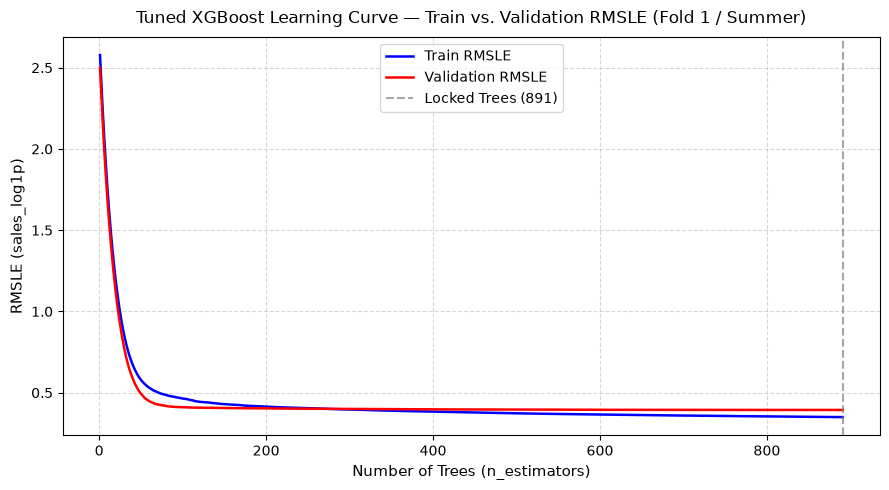

In [12]:
def plot_learning_curve(df: pd.DataFrame, model_type: str = 'XGBoost') -> None:
    train_rmse = df['train_rmse'].tolist()
    val_rmse = df['val_rmse'].tolist()
    epochs = range(1, len(train_rmse) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs, train_rmse, label='Train RMSLE', color='blue', linewidth=1.8
    )
    plt.plot(
        epochs, val_rmse, label='Validation RMSLE', color='red', linewidth=1.8
    )
    plt.axvline(
        x=len(epochs),
        color='gray',
        linestyle='--',
        alpha=0.7,
        label=f'Locked Trees ({len(epochs)})',
    )

    plt.title(
        f'Tuned {model_type} Learning Curve — Train vs. Validation RMSLE (Fold 1 / Summer)',
        fontsize=12,
        pad=10,
    )
    plt.xlabel('Number of Trees (n_estimators)', fontsize=11)
    plt.ylabel('RMSLE (sales_log1p)', fontsize=11)
    plt.legend(frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Extract cached learning history
hist_df = pd.read_csv(PROCESSED_DIR / 'tuned_xgb_model_history.csv')  
plot_learning_curve(df=hist_df, model_type='XGBoost')  


### What the Learning Curve Tells Us

* **Fast Initial Convergence (Trees `1` to `150`):** Both training and validation RMSLE drop sharply from `~2.50` to below `0.42` within the first `150` trees as the model learns the primary demand drivers (`family`, recent sales lags, and promotions).

* **Lower Variance in the Validation Window:** Up to around tree `300`, validation error sits slightly below training error because the 16-day August validation window represents a calm, regular shopping period compared to the full 4.5-year training history (which spans multi-year level shifts and holiday extremes).

* **Stable, Well-Regularized Plateau (`891` Locked Trees):** Beyond tree `300`, training error continues to decrease gradually while validation error flattens smoothly at `0.39358` with no upward drift (no U-shape), confirming that subsampling (`subsample = 0.73`, `colsample_bytree = 0.77`) and L1/L2 penalties prevent overfitting at `max_depth = 9`.

## 9. Model Explainability (Permutation Importance & SHAP)

To understand how our tuned **XGBoost** model makes decisions on the validation window (`2017-07-31` to `2017-08-15`), we use two complementary methods:
1. **Permutation Importance:** Measures how much the validation error (RMSLE) increases when each feature is randomly shuffled.

2. **SHAP Summary Plot (Beeswarm):** Shows both the global ranking of features and the direction of their impact (whether high values push sales predictions up or down).

In [13]:
perm = permutation_importance(
    estimator=tuned_xgb_model,
    X=X_valid_trimmed_summer,
    y=y_valid_trimmed_summer,
    scoring='neg_root_mean_squared_error',
    n_repeats=5,
    random_state=42,
)

perm_df = pd.DataFrame({
    'feature': X_valid_trimmed_summer.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

display(perm_df.round(5))

,feature,importance_mean,importance_std
0,family,0.67835,0.00487
1,sales_log1p_lag16,0.62783,0.00178
2,sales_log1p_lag21_rolling_mean_28,0.62323,0.00183
3,onpromotion,0.46594,0.00359
4,sales_dow_mean_3w,0.20484,0.00139
5,sales_log1p_lag21,0.14229,0.00154
6,store_nbr,0.06496,0.00131
7,sales_log1p_lag21_rolling_mean_14,0.03391,0.00041
8,sales_log1p_lag28,0.02798,0.00065
9,dayofweek,0.02512,0.00028


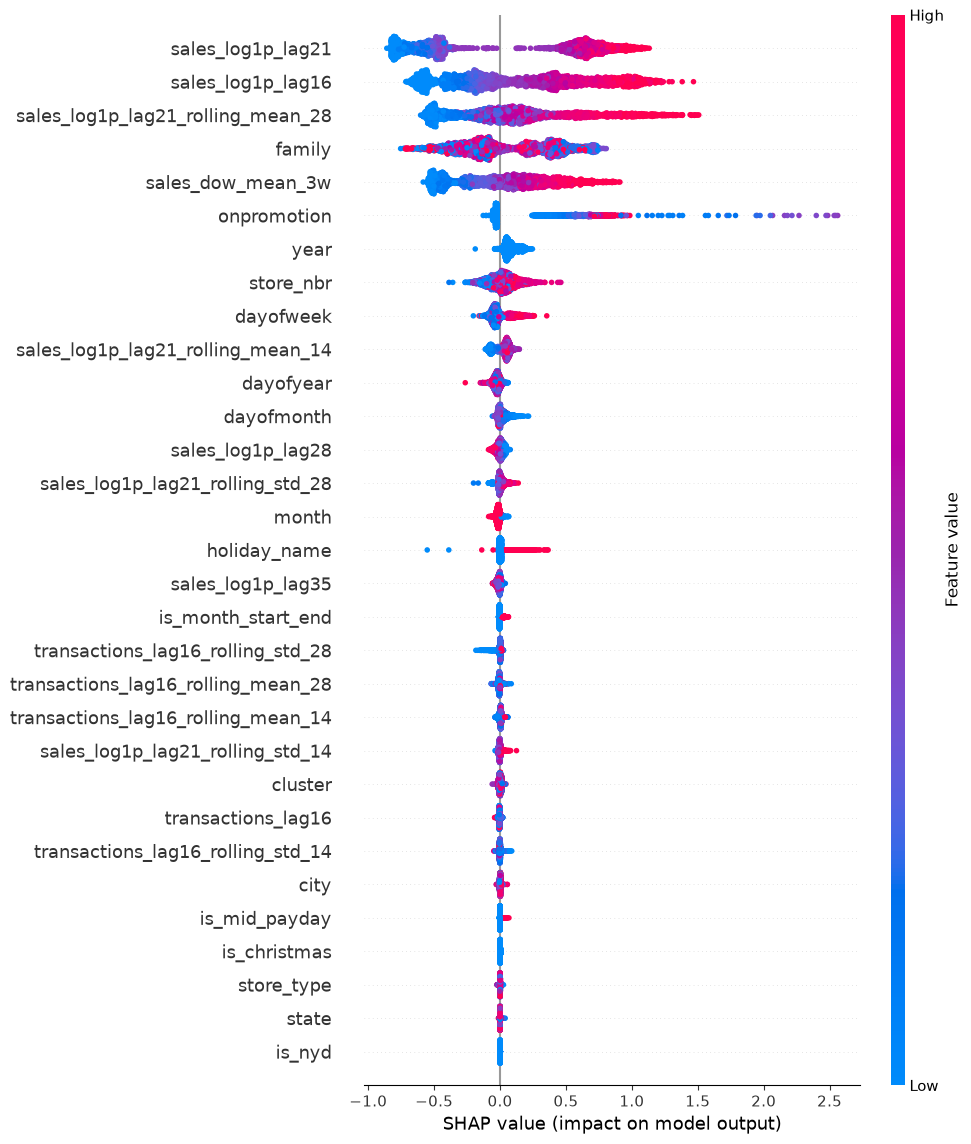

In [14]:
# Randomly choose 3000 rows from the validation set
X_sample = X_valid_trimmed_summer.sample(3000, random_state=42)
contribs = tuned_xgb_model.get_booster().predict(
    xgb.DMatrix(X_sample, enable_categorical=True), 
    pred_contribs=True
)

# Convert category columns to numeric codes strictly for dot color-mapping in the plot
X_disp = X_sample.assign(
    **{c: X_sample[c].cat.codes for c in X_sample.select_dtypes('category')}
)
shap_values = shap.Explanation(
    values=contribs[:, :-1],
    base_values=contribs[:, -1],
    data=X_disp.values,
    feature_names=list(X_sample.columns),
)

shap.plots.beeswarm(shap_values, max_display=31) #show all features

### What the Explainability Results Tell Us

1. **Top Demand Anchors (SHAP vs. Permutation Importance):**  
   Both explainability techniques demonstrate that historical momentum dominates baseline predictions:
   * **TreeSHAP Global Ranking:** Identifies `sales_log1p_lag21`, `sales_log1p_lag16`, `sales_log1p_lag21_rolling_mean_28`, `family`, `sales_dow_mean_3w`, and `onpromotion` as the top contributors across all validation samples.

   * **Permutation Importance:** Confirms that shuffling `family`, `sales_log1p_lag16`, `rolling_mean_28`, `onpromotion`, `sales_dow_mean_3w`, and `sales_log1p_lag21` causes the steepest metric degradation on the fixed model.

2. **Direction and Magnitude of Feature Effects (SHAP Beeswarm Insights):**  
   * **Historical Sales Momentum (`lag21`, `lag16`, `rolling_mean_28`, `sales_dow_mean_3w`):** High historical sales (red dots) push predictions strongly to the right (up to $+1.5$ in log space), while low/zero historical sales (blue clusters) pull predictions sharply to the left ($-0.4$ to $-0.8$).

   * **Catalyst Effect of Promotions (`onpromotion`):** Exhibits the longest positive tail in the entire model (up to $+2.5$). The spread shows that having `onpromotion > 0` acts as a powerful demand catalyst: even a small number of items on promotion (blue/purple dots) is enough to trigger a sharp positive surge in predicted sales.

   * **Day-of-Week Seasonality (`dayofweek`):** High values (weekends) consistently push predictions to the right, capturing peak grocery footfall across Ecuadorian stores.
   
   * **Inactive Seasonal Flags in August:** Features such as `is_christmas` and `is_nyd` stay pinned at exactly $0.0$ SHAP impact, as their indicators remain zero throughout the late-summer validation window.

**Conclusion:** The model captures baseline demand levels, weekly cycles, and promotional sensitivity without irrational feature behaviors. We now lock the XGBoost pipeline and proceed to our second model family: **LightGBM**.

## 10. Second Model Family: LightGBM & Optuna Tuning

To build a strong ensemble, we pair our depth-wise **XGBoost** model with **LightGBM**, which grows trees **leaf-wise (best-first)**. We keep `max_depth = -1` (unlimited) so `num_leaves` directly controls tree complexity, allowing LightGBM to build asymmetric trees whose errors complement XGBoost when blended.

Since the 3 dropped features were removed due to data redundancy (`holiday_name`, `is_earthquake_period`) and macroeconomic noise (`oil_price`), we carry forward the locked 31-feature set (**`TRIMMED_FEATURES`**) into a 3-step pipeline:
1. **Baseline LightGBM Model:** Train a default `LGBMRegressor` on Fold 1 (`2017-07-31` to `2017-08-15`).

2. **Bayesian Hyperparameter Tuning (Optuna):** Optimize `num_leaves`, `learning_rate`, `min_child_samples`, `subsample`, `colsample_bytree`, and L1/L2 penalties across 25 trials.

3. **4-Fold Seasonal Cross-Validation:** Check generalization across all 4 seasonal windows and lock in `FINAL_LGBM_PARAMS`.

In [15]:
def train_evaluate_lightgbm(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_valid: pd.DataFrame,
    y_valid: pd.Series,
    params: dict = None,
    verbose: int = 50,
    model_path: Path = None,
) -> tuple[lgb.LGBMRegressor, float, pd.Series]:
    """Train (or load from disk) a LightGBM regressor and evaluate validation RMSLE."""

    history_path = (
        model_path.with_name(f'{model_path.stem}_history.csv')
        if model_path
        else None
    )

    # --- 1. CASE: CACHE EXISTS (Load model + learning history & replay exact console logs) ---
    if model_path and model_path.exists() and history_path.exists():
        print(f'Loading cached model from {model_path}...\n')
        
        booster = lgb.Booster(model_file=str(model_path))

        hist_df = pd.read_csv(history_path)
        train_rmse_list = hist_df['train_rmse'].tolist()
        val_rmse_list = hist_df['val_rmse'].tolist()
        best_iter = int(hist_df['best_iteration'].iloc[0])

        if verbose:
            step = int(verbose) if isinstance(verbose, int) and verbose > 0 else 50
            for i in range(1, len(train_rmse_list) + 1):
                if i % step == 0 or i == len(train_rmse_list):
                    print(
                        f"[{i}]\tvalidation_0's rmse: {train_rmse_list[i-1]:.5f}\tvalidation_1's rmse: {val_rmse_list[i-1]:.5f}"
                    )

        raw_preds = booster.predict(X_valid, num_iteration=best_iter)

        model = lgb.LGBMRegressor()
        model._Booster = booster
        model._best_iteration = best_iter

    # --- 2. CASE: NO CACHE (Train from scratch and save both model & history) ---
    else:
        default_config = {
            'objective': 'regression',
            'random_state': 42,
            'n_jobs': 6,
            'n_estimators': 2500,
            'learning_rate': 0.05,
            'early_stopping_rounds': 50,
            'metric': 'rmse',
            'max_depth': -1,
            'num_leaves': 31,
            'min_child_samples': 20,
            'subsample': 1.0,
            'subsample_freq': 1, # enable subsample and apply it to every tree
            'colsample_bytree': 1.0,
            'reg_alpha': 0.0,
            'reg_lambda': 0.0,
            'verbosity': -1,
        }

        if params:
            default_config.update(params)

        early_stop_rounds = default_config.pop('early_stopping_rounds', None)

        model = lgb.LGBMRegressor(**default_config)

        callbacks = []
        if early_stop_rounds is not None:
            callbacks.append(
                lgb.early_stopping(stopping_rounds=early_stop_rounds, verbose=False)
            )
        if verbose and verbose > 0:
            callbacks.append(lgb.log_evaluation(period=verbose))

        model.fit(
            X_train,
            y_train,
            eval_X=(X_train, X_valid),
            eval_y=(y_train, y_valid),
            eval_names=['validation_0', 'validation_1'],
            eval_metric='rmse',
            callbacks=callbacks,
        )

        evals_res = model.evals_result_
        train_rmse_list = evals_res['validation_0']['rmse']
        val_rmse_list = evals_res['validation_1']['rmse']
        best_iter = getattr(model, 'best_iteration_', None)
        if not best_iter:
            best_iter = len(train_rmse_list)

        if model_path:
            os.makedirs(model_path.parent, exist_ok=True)
            model.booster_.save_model(str(model_path))
            pd.DataFrame({
                'train_rmse': train_rmse_list,
                'val_rmse': val_rmse_list,
                'best_iteration': best_iter,
            }).to_csv(history_path, index=False)
            print(f'Model and its history saved to {model_path}')

        raw_preds = model.predict(X_valid, num_iteration=best_iter)

    preds_valid = pd.Series(
        np.clip(raw_preds, 0, None),
        index=X_valid.index,
        name='preds_log1p',
    )

    val_rmsle = root_mean_squared_error(y_valid, preds_valid)

    if verbose:
        has_es = best_iter < len(train_rmse_list)
        iter_label = (
            f'Best Iteration: {best_iter}' if has_es else f'Total Trees: {len(train_rmse_list)}'
        )
        print(f'\n--- Validation RMSLE: {val_rmsle:.5f} ({iter_label}) ---')

    return model, val_rmsle, preds_valid


# Train (or load) Baseline LightGBM model on Fold 1 with the 31 TRIMMED_FEATURES

baseline_lgbm_model, baseline_lgbm_rmsle, baseline_lgbm_preds = train_evaluate_lightgbm(
    X_train=X_train_trimmed_summer,
    y_train=y_train_trimmed_summer,
    X_valid=X_valid_trimmed_summer,
    y_valid=y_valid_trimmed_summer,
    verbose=50,
    model_path=PROCESSED_DIR / 'baseline_lgbm_model.json',
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/baseline_lgbm_model.json...

[50]	validation_0's rmse: 0.64017	validation_1's rmse: 0.51955
[100]	validation_0's rmse: 0.52635	validation_1's rmse: 0.44834
[150]	validation_0's rmse: 0.49449	validation_1's rmse: 0.44321
[200]	validation_0's rmse: 0.47275	validation_1's rmse: 0.43811
[250]	validation_0's rmse: 0.45989	validation_1's rmse: 0.43374
[300]	validation_0's rmse: 0.44942	validation_1's rmse: 0.42883
[350]	validation_0's rmse: 0.44104	validation_1's rmse: 0.42701
[400]	validation_0's rmse: 0.43576	validation_1's rmse: 0.42492
[450]	validation_0's rmse: 0.43010	validation_1's rmse: 0.42272
[500]	validation_0's rmse: 0.42620	validation_1's rmse: 0.42007
[550]	validation_0's rmse: 0.42269	validation_1's rmse: 0.41867
[600]	validation_0's rmse: 0.41911	validation_1's rmse: 0.41802
[650]	validation_0's rmse: 0.41633	validation_1's rmse: 0.41663
[700]	validation_0's rmse: 0.41325	validation_1's rms

In [16]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna_tuning_lightgbm(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    feature_cols: list[str] = TRIMMED_FEATURES,
    n_trials: int = 25,
    n_startup_trials: int = 5,
    seed: int = 42,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict, float]:
    """Runs hyperparameter tuning using Optuna across specified CV fold(s).
    Evaluates the Mean RMSLE across the given fold(s). Caches all trials to a CSV
    file so subsequent notebook runs replay instantly without retraining.
    """
    csv_path = output_dir / 'optuna_study_results_lgbm.csv'
    os.makedirs(output_dir, exist_ok=True)

    # --- 1. CASE: CACHE EXISTS (Instant Replay) ---
    if csv_path.exists():
        print(
            f'Found cached Optuna results in {csv_path}. Loading without retraining...\n'
        )
        study_df = pd.read_csv(csv_path)

        print(
            f'Replaying {len(study_df)} cached trials for folds: {list(cv_windows.keys())}...\n'
        )
        
        for _, row in study_df.iterrows():
            print(
                f"Trial {int(row['trial_number']):02d} | "
                f"lr: {row['learning_rate']:.5f}, leaves: {int(row['num_leaves'])}, "
                f"min_child: {int(row['min_child_samples']):3d}, "
                f"sub: {row['subsample']:.5f}, col: {row['colsample_bytree']:.5f}, "
                f"reg_alpha: {row['reg_alpha']:.5f}, reg_lambda: {row['reg_lambda']:.5f} | "
                f"Mean Val RMSLE: {row['val_rmsle']:.5f}"
            )

        best_row = study_df.loc[study_df['val_rmsle'].idxmin()]
        best_value = best_row['val_rmsle']

        param_keys = [
            'learning_rate',
            'num_leaves',
            'min_child_samples',
            'subsample',
            'colsample_bytree',
            'reg_alpha',
            'reg_lambda',
        ]

        best_params = best_row[param_keys].to_dict()
        best_params['num_leaves'] = int(best_params['num_leaves'])
        best_params['min_child_samples'] = int(best_params['min_child_samples'])

        print(f'\n--- Best Mean Val RMSLE: {best_value:.5f} ---')
        print('Best Hyperparameters:')
        for k, v in best_params.items():
            print(f'  {k}: {v}')

        return study_df, best_params, best_value

    # --- 2. PRE-SPLIT DATASETS (One-off pre-processing to avoid splitting inside the loop) ---
    print(
        f'Pre-splitting datasets for {len(cv_windows)} fold(s) to optimize memory...'
    )

    fold_datasets = {}
    for fold_name, start_date in cv_windows.items():
        X_tr, y_tr, X_val, y_val = split_train_dataset(
            df=df,
            feature_cols=feature_cols,
            target_col='sales_log1p',
            val_start=start_date,
            val_days=16,
        )
        fold_datasets[fold_name] = (X_tr, y_tr, X_val, y_val)

    # --- 3. OBJECTIVE FUNCTION ---
    def objective(trial: optuna.Trial) -> float:
        params = {
            'n_estimators': 3500,
            'learning_rate': trial.suggest_float('learning_rate', 0.025, 0.08, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 31, 255),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 200, log=True),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'subsample_freq': 1,
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        }

        fold_scores = []
        # Loop over all requested folds and evaluate
        for _, (X_tr, y_tr, X_val, y_val) in fold_datasets.items():
            _, val_score, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=params,
                verbose=0,
            )
            fold_scores.append(val_score)

        mean_val_rmsle = float(np.mean(fold_scores))

        print(
            f'Trial {trial.number + 1:02d} | '
            f"lr: {params['learning_rate']:.5f}, leaves: {params['num_leaves']}, "
            f"min_child: {params['min_child_samples']:3d}, "
            f"sub: {params['subsample']:.5f}, col: {params['colsample_bytree']:.5f}, "
            f"reg_alpha: {params['reg_alpha']:.5f}, reg_lambda: {params['reg_lambda']:.5f} | "
            f'Mean Val RMSLE: {mean_val_rmsle:.5f}'
        )

        return mean_val_rmsle

    # --- 4. RUN OPTUNA STUDY ---
    print(
        f'\nStarting Optuna Study ({n_trials} trials, {n_startup_trials} startup trials) across {len(cv_windows)} fold(s)...\n'
    )

    sampler = optuna.samplers.TPESampler(seed=seed, n_startup_trials=n_startup_trials)
    study = optuna.create_study(direction='minimize', sampler=sampler)
    study.optimize(objective, n_trials=n_trials)

    # --- 5. EXPORT RESULTS TO CSV ---
    results = []
    for t in study.trials:
        row = {'trial_number': t.number + 1, 'val_rmsle': t.value}
        row.update(t.params)
        results.append(row)

    study_df = pd.DataFrame(results)
    study_df.to_csv(csv_path, index=False)
    print(f'\nOptuna study results successfully saved to {csv_path}')

    print(f'\n--- Best Mean Val RMSLE: {study.best_value:.5f} ---')
    print('Best Hyperparameters:')
    for k, v in study.best_params.items():
        print(f'  {k}: {v}')

    return study_df, study.best_params, study.best_value



TUNING_WINDOWS = {
    'Fold 1 (Summer Baseline)': '2017-07-31',
    #'Fold 2 (Spring / Easter)': '2017-04-05',
    #'Fold 3 (Winter / Christmas)': '2016-12-19',
    #'Fold 4 (Autumn / Regular)': '2016-09-01' 
}

lgbm_study_df, lgbm_best_params, lgbm_best_rmsle = run_optuna_tuning_lightgbm(
    df=df_train_features,
    cv_windows=TUNING_WINDOWS,
    feature_cols=TRIMMED_FEATURES,
    n_trials=25,
    n_startup_trials=5,
    seed=42,
    output_dir=PROCESSED_DIR
)

Found cached Optuna results in /home/user/myprojects/store-sales-forecasting/data/processed/optuna_study_results_lgbm.csv. Loading without retraining...

Replaying 25 cached trials for folds: ['Fold 1 (Summer Baseline)']...

Trial 01 | lr: 0.03865, leaves: 244, min_child:  89, sub: 0.79933, col: 0.57801, reg_alpha: 0.00421, reg_lambda: 0.00171 | Mean Val RMSLE: 0.39743
Trial 02 | lr: 0.06847, leaves: 166, min_child:  82, sub: 0.51029, col: 0.98495, reg_alpha: 2.13683, reg_lambda: 0.00707 | Mean Val RMSLE: 0.40042
Trial 03 | lr: 0.03089, leaves: 72, min_child:  24, sub: 0.76238, col: 0.71597, reg_alpha: 0.01462, reg_lambda: 0.28016 | Mean Val RMSLE: 0.39465
Trial 04 | lr: 0.02940, leaves: 96, min_child:  29, sub: 0.72803, col: 0.89259, reg_alpha: 0.00629, reg_lambda: 0.11401 | Mean Val RMSLE: 0.39883
Trial 05 | lr: 0.04980, leaves: 41, min_child:  61, sub: 0.58526, col: 0.53253, reg_alpha: 6.24514, reg_lambda: 7.28665 | Mean Val RMSLE: 0.40219
Trial 06 | lr: 0.07700, leaves: 37, min_chi

In [17]:
def evaluate_tuned_lightgbm_cv(
    df: pd.DataFrame,
    cv_windows: dict[str, str],
    best_params: dict,
    feature_cols: list[str] = TRIMMED_FEATURES,
    output_dir: Path = PROCESSED_DIR,
) -> tuple[pd.DataFrame, dict]:
    """
    Runs 4-Fold CV for both Baseline LightGBM (default parameters) and tuned LightGBM (Optuna best parameters), compares them directly, and caches the results to CSV for instant replay.
    """
    csv_path = output_dir / 'lgbm_cv_comparison_results.csv'
    os.makedirs(output_dir, exist_ok=True)

    if csv_path.exists():
        print(f'Found cached CV comparison results in {csv_path}. Loading...\n')
        comp_df = pd.read_csv(csv_path)

        print('Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...\n')
        for _, row in comp_df.iterrows():
            print(
                f"{row['fold']:<28} | Base RMSLE: {row['Baseline RMSLE']:.5f} | Tuned RMSLE: {row['Tuned RMSLE']:.5f} | Best Iter (tuned): {int(row['best_iteration'])}"
            )
        print()

    else:
        print('Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...\n')
        eval_params = {'n_estimators': 3500, **best_params}

        records = []
        for fold_name, start_date in cv_windows.items():
            X_tr, y_tr, X_val, y_val = split_train_dataset(
                df=df,
                feature_cols=feature_cols,
                target_col='sales_log1p',
                val_start=start_date,
                val_days=16,
            )

            _, base_rmsle, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=None,
                verbose=0,
            )
            
            tuned_model, tuned_rmsle, _ = train_evaluate_lightgbm(
                X_train=X_tr,
                y_train=y_tr,
                X_valid=X_val,
                y_valid=y_val,
                params=eval_params,
                verbose=0,
            )

            best_iter = int(getattr(tuned_model, 'best_iteration_', None) or eval_params['n_estimators'])
            print(
                f'{fold_name:<28} | Base RMSLE: {base_rmsle:.5f} | Tuned RMSLE: {tuned_rmsle:.5f} | Best Iter (tuned): {best_iter}'
            )

            records.append({
                'fold': fold_name,
                'val_start': start_date,
                'Baseline RMSLE': base_rmsle,
                'Tuned RMSLE': tuned_rmsle,
                'best_iteration': best_iter,
            })

        comp_df = pd.DataFrame(records)
        comp_df['Delta'] = comp_df['Tuned RMSLE'] - comp_df['Baseline RMSLE']
        comp_df['Improv (%)'] = ((comp_df['Delta'] / comp_df['Baseline RMSLE']) * 100).round(2)
        comp_df.to_csv(csv_path, index=False)
        print(f'\nSaved CV comparison results to {csv_path}\n')


    print('=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===')
    print(comp_df.to_string(index=False))
    print('-' * 75)
    print(
        f"Mean Baseline RMSLE : {comp_df['Baseline RMSLE'].mean():.5f}\n"
        f"Mean Tuned RMSLE    : {comp_df['Tuned RMSLE'].mean():.5f} "
        f"({comp_df['Delta'].mean():+.5f})"
    )

    # --- EXTRACT FINAL PRODUCTION PARAMETERS ---
    fold1_best_iter = int(comp_df.loc[0, 'best_iteration'])

    final_lightgbm_params = {
        'n_estimators': fold1_best_iter,
        'max_depth': -1,
        'subsample_freq': 1,
        **best_params,
    }

    print('\n=== Final Locked LightGBM Parameters (Production Ready) ===')
    for k, v in final_lightgbm_params.items():
        if isinstance(v, float):
            print(f'  {k:<18}: {v:.5f}')
        else:
            print(f'  {k:<18}: {v}')

    return comp_df, final_lightgbm_params


lgbm_cv_comparison_df, FINAL_LGBM_PARAMS = evaluate_tuned_lightgbm_cv(
    df=df_train_features,
    cv_windows=CV_WINDOWS,
    best_params=lgbm_best_params,
    feature_cols=TRIMMED_FEATURES,
    output_dir=PROCESSED_DIR,
)

Found cached CV comparison results in /home/user/myprojects/store-sales-forecasting/data/processed/lgbm_cv_comparison_results.csv. Loading...

Running 4-Fold Cross-Validation for Baseline vs Tuned LightGBM...

Fold 1 (Summer Baseline)     | Base RMSLE: 0.39801 | Tuned RMSLE: 0.39202 | Best Iter (tuned): 1133
Fold 2 (Spring / Easter)     | Base RMSLE: 0.45203 | Tuned RMSLE: 0.45032 | Best Iter (tuned): 131
Fold 3 (Winter / Christmas)  | Base RMSLE: 1.23522 | Tuned RMSLE: 1.02694 | Best Iter (tuned): 121
Fold 4 (Autumn / Back-to-School) | Base RMSLE: 0.56407 | Tuned RMSLE: 0.62282 | Best Iter (tuned): 328

=== 4-Fold Cross-Validation Comparison (Baseline vs Tuned) ===
                            fold  val_start  Baseline RMSLE  Tuned RMSLE  best_iteration     Delta  Improv (%)
        Fold 1 (Summer Baseline) 2017-07-31        0.398012     0.392022            1133 -0.005990       -1.50
        Fold 2 (Spring / Easter) 2017-04-05        0.452031     0.450316             131 -0.001715     

### What the LightGBM Cross-Validation Results Tell Us

1. **Consistent Signal on the Target Regime:**  
   On Fold 1 (Summer), tuned LightGBM (`0.39202`) and tuned XGBoost (`0.39358`) converge to nearly identical accuracy. Rather than one algorithm being strictly superior, this confirms that our 31 engineered features capture a stable, reproducible demand signal across both boosting frameworks.

2. **Leaf-Wise vs. Depth-Wise Behavior Across Seasons:**  
   While both models improve 3 out of 4 seasonal folds, their error profiles differ during abrupt seasonal shifts:
   * **LightGBM** (`num_leaves = 235`, `min_child_samples = 11`) grows asymmetric trees leaf-by-leaf, fitting tightly to local interactions in the calm August regime but showing higher sensitivity during the sharp September back-to-school transition (Fold 4).
   
   * **XGBoost** (`max_depth = 9`) enforces uniform depth across branches, acting as a natural regularizer during volatile seasonal transitions (Autumn and Winter).

3. **Why Blending Both Models Works:**  
   Because XGBoost and LightGBM build trees differently and make different errors across store-family series, averaging their predictions is expected to reduce variance and produce a more reliable forecast than either model alone.

## 11. Tuned LightGBM Model & Learning Curve
We now train our final validation **LightGBM** model on Fold 1 (`2017-07-31` to `2017-08-15`) using the locked 31 features (`TRIMMED_FEATURES`) and `FINAL_LGBM_PARAMS` (`n_estimators = 1133`), and inspect its learning curve to verify smooth convergence without overfitting.

In [18]:
tuned_lgbm_model, tuned_lgbm_rmsle, tuned_lgbm_preds_valid = train_evaluate_lightgbm(
    X_train=X_train_trimmed_summer, 
    y_train=y_train_trimmed_summer, 
    X_valid=X_valid_trimmed_summer, 
    y_valid=y_valid_trimmed_summer, 
    params={**FINAL_LGBM_PARAMS, 'early_stopping_rounds': None}, 
    verbose=0,
    model_path=PROCESSED_DIR / 'tuned_lgbm_model.json'
)

print(
    f"Tuned LightGBM (Validation / Fold 1) | Trees: {FINAL_LGBM_PARAMS['n_estimators']} | Validation RMSLE: {tuned_lgbm_rmsle:.5f}"
)

Loading cached model from /home/user/myprojects/store-sales-forecasting/data/processed/tuned_lgbm_model.json...

Tuned LightGBM (Validation / Fold 1) | Trees: 1133 | Validation RMSLE: 0.39202


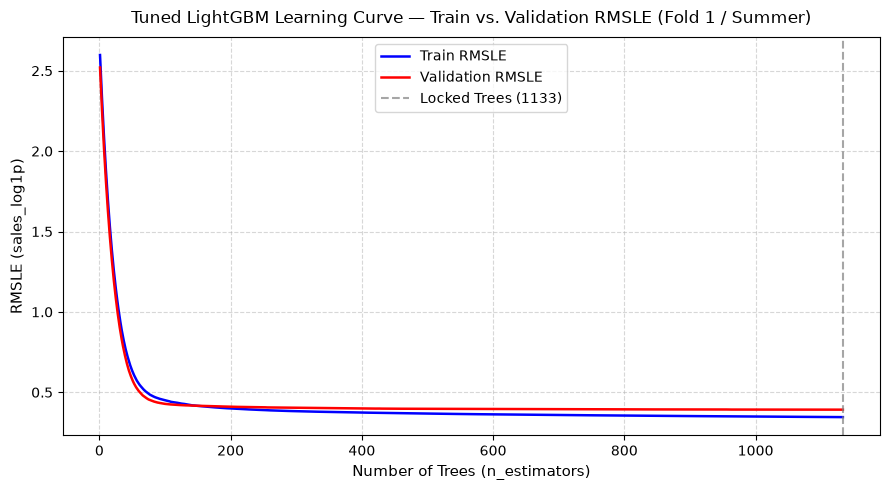

In [19]:
hist_df = pd.read_csv(PROCESSED_DIR / 'tuned_lgbm_model_history.csv')  
plot_learning_curve(df=hist_df, model_type='LightGBM') 

### What the LightGBM Learning Curve Tells Us

* **Fast Convergence & Stable Plateau (`1,133` Trees):** Just like XGBoost, validation error drops rapidly within the first `150` trees and settles into a flat plateau at `0.39202` with no upward drift.

* **Effective Regularization:** Despite allowing up to `235` leaves per tree, feature subsampling (`colsample_bytree = 0.68`) and L1/L2 penalties (`reg_alpha = 0.88`, `reg_lambda = 1.02`) keep the gap between training and validation error tight across all `1,133` iterations.

## 12. Model Ensembling (XGBoost + LightGBM Blend)

In our final modeling step, we combine the validation predictions of our tuned **XGBoost** (`0.39358`) and **LightGBM** (`0.39202`) models on Fold 1 (`2017-07-31` to `2017-08-15`).

Since our evaluation metric (RMSLE) is simply RMSE in `log1p` space, we compute a weighted linear combination directly on the log-transformed predictions:

$$\hat{y}_{\text{blend}} = w \cdot \hat{y}_{\text{LGBM}} + (1 - w) \cdot \hat{y}_{\text{XGB}}, \quad w \in [0, 1]$$

We sweep $w$ from `0.00` (100% XGBoost) to `1.00` (100% LightGBM) in steps of `0.01` to find the optimal ensemble weights and compare all milestone models from this notebook.

Tuned XGBoost Standalone RMSLE  : 0.39358 (Weight: 0.00 LGBM / 1.00 XGB)
Tuned LightGBM Standalone RMSLE : 0.39202 (Weight: 1.00 LGBM / 0.00 XGB)
Equal 50/50 Blend RMSLE         : 0.39123 (Weight: 0.50 LGBM / 0.50 XGB)
Optimal Weighted Blend RMSLE    : 0.39113 (Weight: 0.62 LGBM / 0.38 XGB)



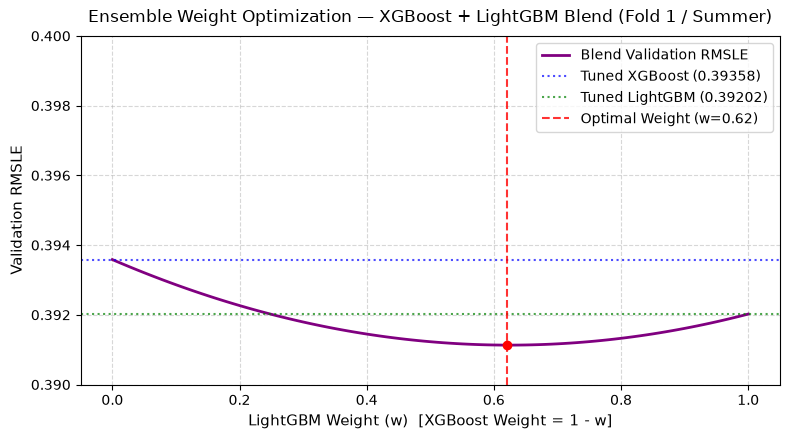

In [20]:
# Sweep ensemble weights w in [0, 1] for LightGBM and (1 - w) for XGBoost
weights = np.linspace(0, 1, 101)
blend_rmsles = []

for w in weights:
    blend_preds = (w * tuned_lgbm_preds_valid) + ((1 - w) * tuned_xgb_preds_valid)
    score = root_mean_squared_error(y_valid_trimmed_summer, blend_preds)
    blend_rmsles.append(score)

best_idx = int(np.argmin(blend_rmsles))
BEST_LGBM_WEIGHT = float(weights[best_idx])
BEST_XGB_WEIGHT = round(1.0 - BEST_LGBM_WEIGHT, 2)
best_blend_rmsle = float(blend_rmsles[best_idx])

# Also evaluate a simple 50/50 equal-weight blend
equal_blend_preds = 0.50 * tuned_lgbm_preds_valid + 0.50 * tuned_xgb_preds_valid
equal_blend_rmsle = root_mean_squared_error(y_valid_trimmed_summer, equal_blend_preds)

print(f'Tuned XGBoost Standalone RMSLE  : {tuned_xgb_rmsle:.5f} (Weight: 0.00 LGBM / 1.00 XGB)')
print(f'Tuned LightGBM Standalone RMSLE : {tuned_lgbm_rmsle:.5f} (Weight: 1.00 LGBM / 0.00 XGB)')
print(f'Equal 50/50 Blend RMSLE         : {equal_blend_rmsle:.5f} (Weight: 0.50 LGBM / 0.50 XGB)')
print(f'Optimal Weighted Blend RMSLE    : {best_blend_rmsle:.5f} (Weight: {BEST_LGBM_WEIGHT:.2f} LGBM / {BEST_XGB_WEIGHT:.2f} XGB)\n')

# --- PLOT ENSEMBLE WEIGHT OPTIMIZATION CURVE ---
plt.figure(figsize=(8, 4.5))
plt.plot(weights, blend_rmsles, color='purple', linewidth=2, label='Blend Validation RMSLE')
plt.axhline(tuned_xgb_rmsle, color='blue', linestyle=':', alpha=0.7, label=f'Tuned XGBoost ({tuned_xgb_rmsle:.5f})')
plt.axhline(tuned_lgbm_rmsle, color='green', linestyle=':', alpha=0.7, label=f'Tuned LightGBM ({tuned_lgbm_rmsle:.5f})')
plt.axvline(BEST_LGBM_WEIGHT, color='red', linestyle='--', alpha=0.8, label=f'Optimal Weight (w={BEST_LGBM_WEIGHT:.2f})')
plt.scatter([BEST_LGBM_WEIGHT], [best_blend_rmsle], color='red', zorder=5)

plt.title('Ensemble Weight Optimization — XGBoost + LightGBM Blend (Fold 1 / Summer)', fontsize=12, pad=10)
plt.xlabel('LightGBM Weight (w)  [XGBoost Weight = 1 - w]', fontsize=11)
plt.ylabel('Validation RMSLE', fontsize=11)
plt.ylim(0.39, 0.40)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [21]:
# --- FINAL MILESTONE SUMMARY TABLE ---
trimmed_xgb_rmsle = float(
    cv_df.loc[
        (cv_df['fold'] == 'Fold 1 (Summer Baseline)') & (cv_df['configuration'].str.contains('Trimmed')),
        'val_rmsle'
    ].iloc[0]
)

final_summary_df = pd.DataFrame([
    {'Model Stage': '1. Baseline XGBoost (All 34 Features)', 'Features': 34, 'Trees': 1389, 'Val RMSLE (Fold 1)': baseline_rmsle},
    {'Model Stage': '2. Trimmed XGBoost (Trimmed 31 Features)', 'Features': 31, 'Trees': 1497, 'Val RMSLE (Fold 1)': trimmed_xgb_rmsle},
    {'Model Stage': '3. Trimmed LightGBM (Trimmed 31 Features)', 'Features': 31, 'Trees': 1915, 'Val RMSLE (Fold 1)': baseline_lgbm_rmsle},
    {'Model Stage': '4. Tuned XGBoost (Optuna)', 'Features': 31, 'Trees': FINAL_XGB_PARAMS['n_estimators'], 'Val RMSLE (Fold 1)': tuned_xgb_rmsle},
    {'Model Stage': '5. Tuned LightGBM (Optuna)', 'Features': 31, 'Trees': FINAL_LGBM_PARAMS['n_estimators'], 'Val RMSLE (Fold 1)': tuned_lgbm_rmsle},
    {'Model Stage': '6. Equal Blend (50% LGBM + 50% XGB)', 'Features': 31, 'Trees': '-', 'Val RMSLE (Fold 1)': equal_blend_rmsle},
    {'Model Stage': f'7. Optimal Blend ({int(BEST_LGBM_WEIGHT*100)}% LGBM + {int(BEST_XGB_WEIGHT*100)}% XGB)', 'Features': 31, 'Trees': '-', 'Val RMSLE (Fold 1)': best_blend_rmsle},
])

final_summary_df['Delta vs. Baseline'] = final_summary_df['Val RMSLE (Fold 1)'] - baseline_rmsle
final_summary_df['Improv (%)'] = ((final_summary_df['Delta vs. Baseline'] / baseline_rmsle) * 100).round(2)

display(final_summary_df.round(5))

,Model Stage,Features,Trees,Val RMSLE (Fold 1),Delta vs. Baseline,Improv (%)
0,1. Baseline XGBoost (All 34 Features),34,1389,0.40022,0.00000,0.00
1,2. Trimmed XGBoost (Trimmed 31 Features),31,1497,0.39767,-0.00255,-0.64
2,3. Trimmed LightGBM (Trimmed 31 Features),31,1915,0.39801,-0.00221,-0.55
3,4. Tuned XGBoost (Optuna),31,891,0.39358,-0.00664,-1.66
4,5. Tuned LightGBM (Optuna),31,1133,0.39202,-0.00820,-2.05
5,6. Equal Blend (50% LGBM + 50% XGB),31,-,0.39123,-0.00899,-2.25
6,7. Optimal Blend (62% LGBM + 38% XGB),31,-,0.39113,-0.00909,-2.27


### What the Ensembling Results Tell Us

* **Genuine Variance Reduction:** Blending our depth-wise **XGBoost** (`0.39358`) and leaf-wise **LightGBM** (`0.39202`) models pushes validation error down to **`0.39113`** (`62% LightGBM + 38% XGBoost`), outperforming both standalone models because their structural errors partially cancel out. While the single-window validation gain is modest, ensembling acts as a robust regularizer, mitigating model-specific variance and reducing the risk of overfitting to a single tree topology.

* **Flat, Robust Optimum:** As the U-shaped curve shows, a simple `50/50` average (`0.39123`) performs almost identically to the optimal `62/38` split (`0.39113`), confirming that the ensemble gain is stable and not sensitive to exact weight tuning.

* **End-to-End Pipeline Gain (`-2.27%`):** Across the full workflow, feature pruning (`34` $\rightarrow$ `31` features), Optuna tuning, and multi-family blending reduced validation RMSLE from `0.40022` to `0.39113`. We now lock in our 31 features, tuned hyperparameters, and `0.62 / 0.38` ensemble weights for final forecasting.